# Stage 9 — conditional mathematical relations
The governed evidence is `results/stage9/numerical_audit.json` (run TA-S09-MATH-R001). Independent proof review remains pending; Stage 8 is geometry-only.


In [1]:
import json
from pathlib import Path

from topoastero.mathematical_relations import (
    gamma_log_tail_bound,
    path_peak_prominences,
    ridge_drift_bound,
    scaling_log_bounds,
)

audit = json.loads(Path('results/stage9/numerical_audit.json').read_text())
assert audit['stage8_decision'] == 'geometry_only' and not audit['population_spectra_used']
assert path_peak_prominences([4., 1., 3.]) == {0: None, 2: 2.}
assert ridge_drift_bound(100, 100, 1, 1/48).candidate_edges_guaranteed
assert gamma_log_tail_bound(audit['gamma_radius'], audit['gamma_shape'], audit['gamma_bins']) <= audit['gamma_alpha']
print('TA-S09-MATH-R001 verified:', audit['path_cases'], 'peak cases;', audit['gamma_exceedances'], 'Gamma exceedances; review pending')


TA-S09-MATH-R001 verified: 128 peak cases; 62 Gamma exceedances; review pending


Example stellar log budgets: ScalingLogBounds(density=0.12, radius=0.20500000000000002, mass=0.495, gravity=0.085)


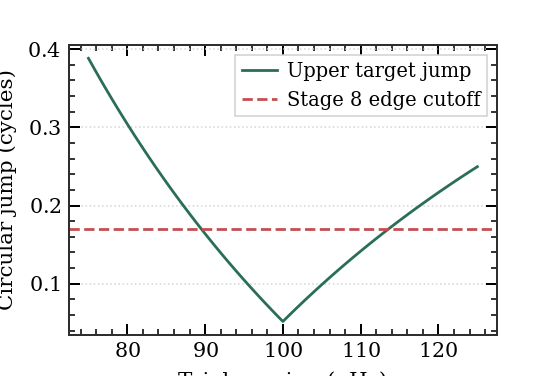

In [2]:
import matplotlib.pyplot as plt
import numpy as np

from topoastero.style import FIGSIZE, data_color, style_axes

trials = np.linspace(75, 125, 101)
upper = [ridge_drift_bound(100, float(x), 1, 1/48).upper_jump_cycles for x in trials]
fig, ax = plt.subplots(figsize=FIGSIZE['single'])
ax.plot(trials, upper, color=data_color('reference'), label='Upper target jump')
ax.axhline(.17, color=data_color('threshold'), linestyle='--', label='Stage 8 edge cutoff')
style_axes(ax, xlabel='Trial spacing (µHz)', ylabel='Circular jump (cycles)', legend=True)
print('Example stellar log budgets:', scaling_log_bounds(.02, .03, .01, dnu_systematic_log=.04, numax_systematic_log=.05))
